In [1]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bambi as bmb
import arviz as az
from matplotlib.ticker import NullLocator

plt.rcParams.update({
    "font.family": "Libertinus Serif",
    "font.size": CORPS,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

NACHTBLAUW, STEENGRIJS = KLEUR_NACHT, "#96999B"
PALET = ["#0067B9", "#FF9527", "#00859B", "#007044", "#E100A3", "#9569BE", "#CC982F"]

SEED = 42
NACHTCATS = ["nacht", "avondschemering", "ochtendschemering"]
SLEUTEL = ["archive_file", "Incident Number"]

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [2]:
DATA = Path("../../data/algemeen")
FIG = Path("../../fig/H8"); FIG.mkdir(parents=True, exist_ok=True)

def bewaar(fig, naam):
    for ext in ("png",):
        pas_breedte_aan(fig, tight=True)
        fig.savefig(FIG / f"{naam}.{ext}", dpi=300, bbox_inches="tight")

In [3]:
map_macro = Path("../../data/algemeen/gebeurtenisdata_macro")
excel_files = sorted([f for f in map_macro.glob("*.xlsx")])

print(len(excel_files))

dataframes = []
for file in excel_files:
    try:
        df = pd.read_excel(file)
        dataframes.append(df)
    except Exception as e:
        print(file.name)

df_macro = pd.concat(dataframes, ignore_index=True)


198
._MA#30830.xlsx


In [4]:
df_w3 = pd.read_excel("../../data/H8/geluidsoverlast_w3_nacht_allepersonen.xlsx")

In [5]:
PRAKTIJKEN = {"yelling": "roepen", "singing": "zingen", "arguing": "ruzie maken",
              "scolding": "schelden", "playing inn music": "herbergmuziek",
              "doorbell ringing": "deurbellen", "traffic noise": "verkeer"}

ontbreekt = [k for k in PRAKTIJKEN if k not in df_w3.columns]
assert not ontbreekt, f"ontbrekende labelkolommen: {ontbreekt}"

print(f"{len(df_w3):,} personen, "
      f"{df_w3.drop_duplicates(subset=SLEUTEL).shape[0]:,} gebeurtenissen")

1,823 personen, 819 gebeurtenissen


In [6]:
JAREN = np.arange(1876, 1940)


In [7]:
db_uniek = df_macro.drop_duplicates(subset=SLEUTEL)
db3_nacht = db_uniek[(db_uniek["district"] == 3)
                     & (db_uniek["astro"].isin(NACHTCATS))]

noemer = db3_nacht.groupby("year").size().reindex(JAREN, fill_value=0)
noemer = noemer[noemer > 0]

w3_nacht = df_w3[df_w3["astronomical_category"].isin(NACHTCATS)]

print(f"noemer: {noemer.sum():,} nachtelijke gebeurtenissen over {len(noemer)} bewaarde jaren")
print(f"geannoteerd nachtelijk: {w3_nacht.drop_duplicates(subset=SLEUTEL).shape[0]:,} gebeurtenissen")

noemer: 15,069 nachtelijke gebeurtenissen over 38 bewaarde jaren
geannoteerd nachtelijk: 818 gebeurtenissen


In [8]:
def periode_van(jaren):
    return np.where(jaren <= 1914, "Voor 1914", "Interbellum")

per_gebeurtenis = (w3_nacht.groupby(SLEUTEL)[list(PRAKTIJKEN)].max()
                           .join(w3_nacht.groupby(SLEUTEL)["year"].first()))
per_gebeurtenis["periode"] = periode_van(per_gebeurtenis["year"])

noemer_periode = noemer.groupby(periode_van(noemer.index)).sum()

tabel = (per_gebeurtenis.groupby("periode")[list(PRAKTIJKEN)].sum()
                        .rename(columns=PRAKTIJKEN).T)
tabel_per_1000 = tabel.div(noemer_periode, axis=1).mul(1000).round(1)

print(tabel.astype(int).to_string())
print("\nper 1.000 nachtelijke gebeurtenissen:")
print(tabel_per_1000.to_string())

periode        Interbellum  Voor 1914
roepen                  43        174
zingen                  28        124
ruzie maken             13         77
schelden                21         30
herbergmuziek           21         21
deurbellen              11         12
verkeer                  5          6

per 1.000 nachtelijke gebeurtenissen:
periode        Interbellum  Voor 1914
roepen                 6.3       21.2
zingen                 4.1       15.1
ruzie maken            1.9        9.4
schelden               3.1        3.7
herbergmuziek          3.1        2.6
deurbellen             1.6        1.5
verkeer                0.7        0.7


In [9]:
GROEPEN = {
    "Uitbundigheid en conflict": ["yelling", "arguing", "singing"],
    "Verbaal geweld": ["scolding"],
    "Herbergmuziek": ["playing inn music"],
}

def per_jaar(kolommen):
    sub = per_gebeurtenis[per_gebeurtenis[kolommen].eq(1).any(axis=1)]
    return sub.groupby("year").size().reindex(noemer.index, fill_value=0)

tellingen = pd.DataFrame({g: per_jaar(k) for g, k in GROEPEN.items()})
tellingen["noemer"] = noemer
tellingen["periode"] = periode_van(tellingen.index)

print(tellingen.groupby("periode")[["noemer"] + list(GROEPEN)].sum().to_string())

             noemer  Uitbundigheid en conflict  Verbaal geweld  Herbergmuziek
periode                                                                      
Interbellum    6853                         79              21             21
Voor 1914      8216                        325              30             21


In [10]:
lang = (tellingen.reset_index(names="jaar")
        .melt(id_vars=["jaar", "noemer", "periode"], value_vars=list(GROEPEN),
              var_name="groep", value_name="aantal"))
lang["log_noemer"] = np.log(lang["noemer"])
lang["periode"] = pd.Categorical(lang["periode"], ["Voor 1914", "Interbellum"])

print(lang.groupby(["groep", "periode"], observed=True)["aantal"].sum().unstack().to_string())

periode                    Voor 1914  Interbellum
groep                                            
Herbergmuziek                     21           21
Uitbundigheid en conflict        325           79
Verbaal geweld                    30           21


In [11]:
lang = (tellingen.reset_index(names="jaar")
        .melt(id_vars=["jaar", "noemer", "periode"], value_vars=list(GROEPEN),
              var_name="groep", value_name="aantal"))
lang["log_noemer"] = np.log(lang["noemer"])
lang["periode"] = pd.Categorical(lang["periode"], ["Voor 1914", "Interbellum"])

print(lang.groupby(["groep", "periode"], observed=True)["aantal"].sum().unstack().to_string())

periode                    Voor 1914  Interbellum
groep                                            
Herbergmuziek                     21           21
Uitbundigheid en conflict        325           79
Verbaal geweld                    30           21


In [12]:
model = bmb.Model("aantal ~ groep * periode + offset(log_noemer)",
                  lang, family="negativebinomial")
idata = model.fit(draws=2000, tune=2000, target_accept=0.9, random_seed=SEED)

print(az.summary(idata, round_to=2).to_string())
print("\ndivergenties:", int(idata.sample_stats["diverging"].sum()))

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, Intercept, groep, periode, groep:periode]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 6 seconds.


                                                     mean    sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
alpha                                                5.15  2.15    2.05     9.08       0.03     0.02   6944.50   4276.73    1.0
Intercept                                           -5.80  0.24   -6.25    -5.33       0.00     0.00   3802.72   4372.38    1.0
groep[Uitbundigheid en conflict]                     1.33  0.29    0.78     1.86       0.00     0.00   4016.67   4312.61    1.0
groep[Verbaal geweld]                               -0.00  0.34   -0.65     0.64       0.01     0.00   4243.91   4465.70    1.0
periode[Voor 1914]                                  -0.12  0.35   -0.81     0.51       0.01     0.00   3451.67   4449.06    1.0
groep:periode[Uitbundigheid en conflict, Voor 1914]  1.43  0.41    0.67     2.19       0.01     0.00   3498.23   4285.74    1.0
groep:periode[Verbaal geweld, Voor 1914]             0.28  0.48   -0.63     1.19       0.01     0.01   3

In [13]:
raster = (lang[["groep", "periode"]].drop_duplicates()
          .assign(log_noemer=np.log(1000)).reset_index(drop=True))
pred = model.predict(idata, data=raster, inplace=False, kind="response_params")
mu = az.extract(pred, group="posterior")["mu"].values

raster["gem"] = mu.mean(axis=1)
raster[["lo", "hi"]] = np.quantile(mu, [0.03, 0.97], axis=1).T
print(raster.round(2).to_string(index=False))

                    groep     periode  log_noemer   gem    lo    hi
Uitbundigheid en conflict   Voor 1914        6.91 42.86 33.54 54.55
Uitbundigheid en conflict Interbellum        6.91 11.59  8.54 15.26
           Verbaal geweld   Voor 1914        6.91  3.66  2.34  5.34
           Verbaal geweld Interbellum        6.91  3.13  1.89  4.80
            Herbergmuziek   Voor 1914        6.91  2.78  1.65  4.29
            Herbergmuziek Interbellum        6.91  3.13  1.89  4.74

In [14]:
post = idata.posterior["groep:periode"]
print(post.coords["groep:periode_dim"].values)

for cat in ["Uitbundigheid en conflict, Voor 1914", "Verbaal geweld, Voor 1914"]:
    k = float((post.sel({"groep:periode_dim": cat}) > 0).mean())
    print(f"{cat}: P(sterkere daling dan herbergmuziek) = {k:.2f}")

['Uitbundigheid en conflict, Voor 1914' 'Verbaal geweld, Voor 1914']
Uitbundigheid en conflict, Voor 1914: P(sterkere daling dan herbergmuziek) = 1.00
Verbaal geweld, Voor 1914: P(sterkere daling dan herbergmuziek) = 0.73


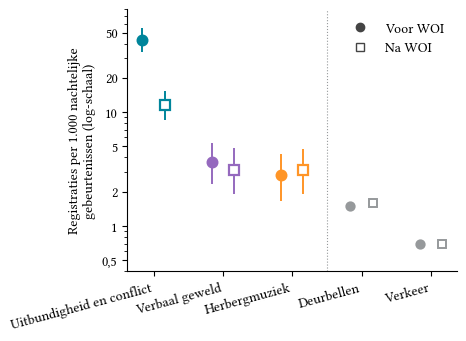

In [15]:
KLEUREN = {"Uitbundigheid en conflict": "#00859B",
           "Verbaal geweld": "#9569BE",
           "Herbergmuziek": "#FF9527"}
VOLGORDE = list(KLEUREN)
ZELDZAAM = {"deurbellen": "doorbell ringing", "verkeer": "traffic noise"}

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, 3.4))

for i, groep in enumerate(VOLGORDE):
    for j, (per, verschuiving) in enumerate([("Voor 1914", -0.16), ("Interbellum", 0.16)]):
        r = raster[(raster["groep"] == groep) & (raster["periode"] == per)].iloc[0]
        x = i + verschuiving
        ax.vlines(x, r["lo"], r["hi"], color=KLEUREN[groep], lw=1.4)
        ax.plot(x, r["gem"], "o" if j == 0 else "s", color=KLEUREN[groep],
                ms=7, mfc=KLEUREN[groep] if j == 0 else "white", mew=1.6)

# niet-gemodelleerde praktijken als open punten
for k, (nl, kol) in enumerate(ZELDZAAM.items()):
    for j, (per, verschuiving) in enumerate([("Voor 1914", -0.16), ("Interbellum", 0.16)]):
        waarde = tabel_per_1000.loc[nl, per]
        ax.plot(len(VOLGORDE) + k + verschuiving, waarde, "o" if j == 0 else "s",
                color=STEENGRIJS, ms=6, mfc=STEENGRIJS if j == 0 else "white", mew=1.4)

ax.set_xticks(range(len(VOLGORDE) + len(ZELDZAAM)))
ax.set_xticklabels(VOLGORDE + [n.capitalize() for n in ZELDZAAM],
                   fontsize=CORPS, rotation=15, ha="right")
ax.axvline(len(VOLGORDE) - 0.5, color=STEENGRIJS, lw=0.8, ls=":")
ax.set_yscale("log")
ax.set_ylim(0.4, 80)
ax.set_yticks([0.5, 1, 2, 5, 10, 20, 50])
ax.set_yticklabels(["0,5", "1", "2", "5", "10", "20", "50"])
ax.set_ylabel("Registraties per 1.000 nachtelijke\ngebeurtenissen (log-schaal)", fontsize=CORPS)
stijl = [plt.Line2D([], [], marker="o", ls="", color="#444", label="Voor WOI"),
         plt.Line2D([], [], marker="s", ls="", color="#444", mfc="white", label="Na WOI")]
ax.legend(handles=stijl, frameon=False, fontsize=CORPS, loc="upper right")

#bewaar(fig, "praktijken_per_periode")

In [16]:
drie = per_gebeurtenis.assign(
    blok=pd.cut(per_gebeurtenis["year"], [1876, 1891, 1914, 1939],
                labels=["1877-1891", "1912-1914", "1919-1939"]))
n_blok = noemer.groupby(pd.cut(noemer.index, [1876, 1891, 1914, 1939],
                               labels=["1877-1891", "1912-1914", "1919-1939"])).sum()
print((drie.groupby("blok", observed=True)[list(PRAKTIJKEN)].sum()
         .div(n_blok, axis=0).mul(1000).round(1).rename(columns=PRAKTIJKEN).T))

blok           1877-1891  1912-1914  1919-1939
roepen              20.1       28.4        6.3
zingen              15.7       11.0        4.1
ruzie maken         10.1        4.6        1.9
schelden             3.9        1.8        3.1
herbergmuziek        1.0       12.8        3.1
deurbellen           1.1        3.7        1.6
verkeer              0.4        2.7        0.7


/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_44752/1313925459.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  n_blok = noemer.groupby(pd.cut(noemer.index, [1876, 1891, 1914, 1939],


In [17]:
blok12 = per_gebeurtenis[per_gebeurtenis["year"].between(1912, 1914)]
print(blok12.groupby("year")[list(PRAKTIJKEN)].sum().rename(columns=PRAKTIJKEN))
print(blok12[blok12["playing inn music"] == 1].index.get_level_values("archive_file").value_counts())

        roepen  zingen  ruzie maken  schelden  herbergmuziek  deurbellen  \
year                                                                       
1912.0     5.0     3.0          0.0       0.0            2.0         1.0   
1913.0    17.0     6.0          3.0       2.0            7.0         3.0   
1914.0     9.0     3.0          2.0       0.0            5.0         0.0   

        verkeer  
year             
1912.0      2.0  
1913.0      1.0  
1914.0      0.0  
archive_file
MA#17873    6
MA#17875    5
MA#17871    2
MA#17874    1
Name: count, dtype: int64


In [18]:
per_gebeurtenis["blok"] = pd.cut(per_gebeurtenis["year"], [1876, 1891, 1914, 1939],
                                 labels=["1877-1891", "1912-1914", "1919-1939"])

tellingen["blok"] = pd.cut(tellingen.index, [1876, 1891, 1914, 1939],
                           labels=["1877-1891", "1912-1914", "1919-1939"])
model_data = tellingen[~tellingen.index.isin(range(1912, 1915))].copy()
model_data["periode"] = pd.Categorical(
    np.where(model_data.index <= 1891, "1877-1891", "1919-1939"),
    ["1877-1891", "1919-1939"])

print(model_data.groupby("periode", observed=True)[["noemer"] + list(GROEPEN)].sum())

           noemer  Uitbundigheid en conflict  Verbaal geweld  Herbergmuziek
periode                                                                    
1877-1891    7124                        281              28              7
1919-1939    6853                         79              21             21


In [19]:
lang = (model_data.reset_index(names="jaar")
        .melt(id_vars=["jaar", "noemer", "periode"], value_vars=list(GROEPEN),
              var_name="groep", value_name="aantal"))
lang["log_noemer"] = np.log(lang["noemer"])

print(lang.groupby(["groep", "periode"], observed=True)["aantal"].sum().unstack())

periode                    1877-1891  1919-1939
groep                                          
Herbergmuziek                      7         21
Uitbundigheid en conflict        281         79
Verbaal geweld                    28         21


In [20]:
print(model_data["blok"].value_counts(dropna=False))
print(model_data["periode"].value_counts(dropna=False))

blok
1919-1939    21
1877-1891    14
1912-1914     0
Name: count, dtype: int64
periode
1919-1939    21
1877-1891    14
Name: count, dtype: int64


In [21]:
model = bmb.Model("aantal ~ groep * periode + offset(log_noemer)",
                  lang, family="negativebinomial")
idata = model.fit(draws=2000, tune=2000, target_accept=0.9, random_seed=SEED)

print(az.summary(idata, round_to=2).to_string())
print("\ndivergenties:", int(idata.sample_stats["diverging"].sum()))
print("\nreferentie:", idata.posterior["periode"].coords["periode_dim"].values,
      "|", idata.posterior["groep:periode"].coords["groep:periode_dim"].values)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, Intercept, groep, periode, groep:periode]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 18 seconds.


                                                     mean    sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
alpha                                                6.64  2.80    2.62    11.95       0.04     0.03   6202.25   4970.87    1.0
Intercept                                           -6.92  0.39   -7.68    -6.22       0.01     0.01   2058.85   2972.45    1.0
groep[Uitbundigheid en conflict]                     3.77  0.41    3.04     4.57       0.01     0.01   2066.76   3073.16    1.0
groep[Verbaal geweld]                                1.37  0.45    0.55     2.24       0.01     0.01   2202.90   3259.66    1.0
periode[1919-1939]                                   1.11  0.46    0.30     2.03       0.01     0.01   2021.79   3124.33    1.0
groep:periode[Uitbundigheid en conflict, 1919-1939] -2.42  0.50   -3.33    -1.47       0.01     0.01   2069.43   3380.63    1.0
groep:periode[Verbaal geweld, 1919-1939]            -1.35  0.56   -2.39    -0.27       0.01     0.01   2

In [22]:
per_term = idata.posterior["periode"]
print(per_term.coords)

Coordinates:
  * chain        (chain) int64 32B 0 1 2 3
  * draw         (draw) int64 16kB 0 1 2 3 4 5 ... 1994 1995 1996 1997 1998 1999
  * periode_dim  (periode_dim) <U9 36B '1919-1939'


In [23]:
post = idata.posterior
print("P(herbergmuziek nam toe) =",
      float((post["periode"].sel(periode_dim="1919-1939") > 0).mean()))
for cat in post["groep:periode"].coords["groep:periode_dim"].values:
    k = float((post["groep:periode"].sel({"groep:periode_dim": cat}) < 0).mean())
    print(f"P({cat.split(',')[0]} ontwikkelde zich anders dan herbergmuziek) = {k:.2f}")

P(herbergmuziek nam toe) = 0.994625
P(Uitbundigheid en conflict ontwikkelde zich anders dan herbergmuziek) = 1.00
P(Verbaal geweld ontwikkelde zich anders dan herbergmuziek) = 0.99


In [24]:
BLOKKEN = ["1877-1891", "1912-1914", "1919-1939"]
DX = {"1877-1891": -0.22, "1912-1914": 0.0, "1919-1939": 0.22}

# voorspellingen per 1.000 nachtelijke gebeurtenissen uit het model van cel 19
raster = (lang[["groep", "periode"]].drop_duplicates()
          .assign(log_noemer=np.log(1000)).reset_index(drop=True))
pred = model.predict(idata, data=raster, inplace=False, kind="response_params")
mu = az.extract(pred, group="posterior")["mu"].values

raster["gem"] = mu.mean(axis=1)
raster[["lo", "hi"]] = np.quantile(mu, [0.03, 0.97], axis=1).T
print(raster.round(2).to_string(index=False))


                    groep   periode  log_noemer   gem    lo    hi
Uitbundigheid en conflict 1877-1891        6.91 42.90 33.55 54.50
Uitbundigheid en conflict 1919-1939        6.91 11.59  8.70 15.08
           Verbaal geweld 1877-1891        6.91  3.96  2.50  5.81
           Verbaal geweld 1919-1939        6.91  3.12  1.90  4.70
            Herbergmuziek 1877-1891        6.91  1.06  0.45  1.94
            Herbergmuziek 1919-1939        6.91  3.07  1.85  4.61


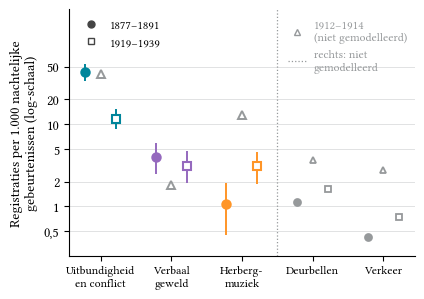

In [25]:
KLEUREN = {"Uitbundigheid en conflict": "#00859B",
           "Verbaal geweld": "#9569BE",
           "Herbergmuziek": "#FF9527"}
VOLGORDE = list(KLEUREN)
ZELDZAAM = {"Deurbellen": "doorbell ringing", "Verkeer": "traffic noise"}

# ruwe aandelen: groepen én zeldzame praktijken, per blok
ruw = pd.DataFrame(
    {g: per_gebeurtenis[per_gebeurtenis[k].eq(1).any(axis=1)]
         .groupby("blok", observed=True).size()
     for g, k in GROEPEN.items()}
    | {nl: per_gebeurtenis[per_gebeurtenis[k].eq(1)]
           .groupby("blok", observed=True).size()
       for nl, k in ZELDZAAM.items()}
).div(n_blok, axis=0).mul(1000)

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, 3.2))

for i, groep in enumerate(VOLGORDE):
    for blok in BLOKKEN:
        x = i + DX[blok]
        if blok == "1912-1914":
            ax.plot(x, ruw.loc[blok, groep], "^", color=STEENGRIJS,
                    ms=6, mfc="white", mew=1.4)
        else:
            r = raster[(raster["groep"] == groep) & (raster["periode"] == blok)].iloc[0]
            ax.vlines(x, r["lo"], r["hi"], color=KLEUREN[groep], lw=1.4)
            ax.plot(x, r["gem"], "o" if blok == BLOKKEN[0] else "s",
                    color=KLEUREN[groep], ms=6,
                    mfc=KLEUREN[groep] if blok == BLOKKEN[0] else "white", mew=1.5)

VORM = {"1877-1891": "o", "1912-1914": "^", "1919-1939": "s"}
for j, nl in enumerate(ZELDZAAM):
    for blok in BLOKKEN:
        ax.plot(len(VOLGORDE) + j + DX[blok], ruw.loc[blok, nl], VORM[blok],
                color=STEENGRIJS, ms=5,
                mfc=STEENGRIJS if blok == BLOKKEN[0] else "white", mew=1.3)

ax.axvline(len(VOLGORDE) - 0.5, color=STEENGRIJS, lw=0.9, ls=":")
ax.set_xticks(range(len(VOLGORDE) + len(ZELDZAAM)))
ax.set_xticklabels(["Uitbundigheid\nen conflict", "Verbaal\ngeweld", "Herberg-\nmuziek"]
                   + list(ZELDZAAM), fontsize=CORPS_KLEIN)
ax.set_xlim(-0.45, len(VOLGORDE) + len(ZELDZAAM) - 0.55)

ax.set_yscale("log")
ax.set_ylim(0.25, 250)  # ruimte voor de legende
ax.set_yticks([0.5, 1, 2, 5, 10, 20, 50])
ax.set_yticklabels(["0,5", "1", "2", "5", "10", "20", "50"])
ax.yaxis.set_minor_locator(NullLocator())
ax.yaxis.grid(True)
ax.set_ylabel("Registraties per 1.000 nachtelijke\ngebeurtenissen (log-schaal)", fontsize=CORPS)

from matplotlib.transforms import blended_transform_factory

# gemodelleerde perioden: links van de stippellijn
stijl = [plt.Line2D([], [], marker="o", ls="", color="#444", ms=5, label="1877–1891"),
         plt.Line2D([], [], marker="s", ls="", color="#444", ms=5, mfc="white",
                    label="1919–1939")]
leg = ax.legend(handles=stijl, frameon=False, fontsize=CORPS_KLEIN, loc="upper left",
                handletextpad=0.6)
ax.add_artist(leg)

# niet gemodelleerd (lichtgrijs): volledig rechts van de stippellijn
grijs = [plt.Line2D([], [], marker="^", ls="", color=STEENGRIJS, ms=5, mfc="white",
                    label="1912–1914\n(niet gemodelleerd)"),
         plt.Line2D([], [], ls=":", color=STEENGRIJS, lw=0.9,
                    label="rechts: niet\ngemodelleerd")]
leg2 = ax.legend(handles=grijs, frameon=False, fontsize=CORPS_KLEIN, loc="upper left",
                 bbox_to_anchor=(len(VOLGORDE) - 0.5, 1.0),
                 bbox_transform=blended_transform_factory(ax.transData, ax.transAxes),
                 handlelength=1.6, handletextpad=0.6)
for t in leg2.get_texts():
    t.set_color(STEENGRIJS)

bewaar(fig, "8.11_praktijken_per_periode")

In [26]:
LABELS = [k for k in PRAKTIJKEN if k in per_gebeurtenis.columns] + ["playing street music"]
LABELS = [k for k in LABELS if k in per_gebeurtenis.columns]

heeft_praktijk = per_gebeurtenis[LABELS].eq(1).any(axis=1)

print(f"N met geannoteerde geluidspraktijk (nachtelijk, wijk 3): {int(heeft_praktijk.sum())}")
print(f"waarvan per blok:\n{per_gebeurtenis.loc[heeft_praktijk, 'blok'].value_counts().sort_index()}")
print(f"\nzonder straatmuziek: {int(per_gebeurtenis[list(PRAKTIJKEN)].eq(1).any(axis=1).sum())}")
print(f"in het model (excl. 1912-1914): "
      f"{int(heeft_praktijk[~per_gebeurtenis['year'].between(1912, 1914)].sum())}")

N met geannoteerde geluidspraktijk (nachtelijk, wijk 3): 489
waarvan per blok:
blok
1877-1891    305
1912-1914     60
1919-1939    124
Name: count, dtype: int64

zonder straatmuziek: 489
in het model (excl. 1912-1914): 429


In [27]:
alle = df_w3.groupby(SLEUTEL)[LABELS].max()
print(f"zonder nachtfilter: {int(alle.eq(1).any(axis=1).sum())}")

zonder nachtfilter: 489


In [28]:
zonder_arguing = [k for k in LABELS if k != "arguing"]
print("zonder arguing:", int(per_gebeurtenis[zonder_arguing].eq(1).any(axis=1).sum()))

zonder arguing: 426


In [29]:
laat = per_gebeurtenis[per_gebeurtenis["year"] >= 1919].copy()
laat["helft"] = np.where(laat["year"] <= 1928, "1919-1928", "1929-1939")
n_helft = noemer[noemer.index >= 1919].groupby(
    np.where(noemer[noemer.index >= 1919].index <= 1928, "1919-1928", "1929-1939")).sum()
print(laat.groupby("helft")[list(PRAKTIJKEN)].sum().div(n_helft, axis=0).mul(1000).round(1).T)

helft              1919-1928  1929-1939
yelling                  8.5        3.9
singing                  4.5        3.6
arguing                  1.7        2.1
scolding                 4.0        2.1
playing inn music        2.6        3.6
doorbell ringing         2.0        1.2
traffic noise            0.6        0.9


In [30]:
alle_verkeer = per_gebeurtenis[per_gebeurtenis["traffic noise"] == 1].index

sel = (df_w3.set_index(SLEUTEL).loc[alle_verkeer].reset_index()
            .drop_duplicates(subset=SLEUTEL))

for _, r in sel.sort_values("year").iterrows():
    kop = (f"{int(r['year'])} | {r.get('E_DATE_clean', '')} | "
           f"{r['archive_file']} #{r['Incident Number']} | "
           f"{r.get('loc_street', '')} | {r.get('astronomical_category', '')}")
    print(f"\n--- {kop} ---")
    print(str(r.get("text", ""))[:700])


--- 1877 | 30/11/1876 | 731#1586 #698.0 |  | nacht ---
Heden nacht hebben wi klacht ontvangen van den genaamden immermans dat er door een inwakingg die zich budine aan eene riool door het huis N 40 in de Wieg straat verschyde malen de wagen van de met beir ruimmers zik daar versteld in bevinden , en dus eene groo te moeite hebben om hunne wagens daar uit te krygen , hetgeen de rust somityd van de inwooners stoore futten Panis et G

--- 1881 | 24/06/1881 | 731#1596 #942.0 |  | nacht ---
24 juny 1881 D PV Devouz 1 ine Dezen nacht ontrent 1 uur heb ik bestatigt dat er op de Keizers lei een evig tawyd gemaakt wuerd , ik bevond my alsdaa op de Teniersplaats oogenblikkelijk nadien , bemerkt ik dat er vif rijtuigen links en rechts reden en gedung nacht ramaer maakte Ik begaf my als dan ter plaats Den genaamde Wiggers huurkouder wonend Hoog straat deed my oagenblikkelijk eene klacht dat de koetsiers dewelke zich rond hem bevonden hem zijnen weg gedurig belet hadden voort te riden dat zijdhebb

In [31]:
BINNEN = {"yelling": "roepen", "singing": "zingen", "arguing": "ruzie maken"}

sub = per_gebeurtenis[per_gebeurtenis["periode"].notna()
                      & ~per_gebeurtenis["year"].between(1912, 1914)].copy()
sub["periode"] = np.where(sub["year"] <= 1891, "1877-1891", "1919-1939")

abs_t = sub.groupby("periode")[list(BINNEN)].sum().rename(columns=BINNEN).T
rel_t = abs_t.div(abs_t.sum()).mul(100).round(1)

print(abs_t.astype(int).to_string())
print("\naandeel binnen de groep (%):")
print(rel_t.to_string())

periode      1877-1891  1919-1939
roepen             143         43
zingen             112         28
ruzie maken         72         13

aandeel binnen de groep (%):
periode      1877-1891  1919-1939
roepen            43.7       51.2
zingen            34.3       33.3
ruzie maken       22.0       15.5


In [32]:
w3_pers = df_w3[df_w3["astronomical_category"].isin(NACHTCATS)].copy()

KLASSE3 = {**{i: "Elite" for i in range(1, 4)},
           **{i: "Middenklasse" for i in (4, 5)},
           **{i: "Arbeidersklasse" for i in range(6, 13)}}

hisclass = pd.to_numeric(w3_pers["P_PROF_hisclass"], errors="coerce")
w3_pers["klasse3"] = hisclass.astype("Int64").map(KLASSE3)

w3_pers["leeftijd3"] = pd.cut(pd.to_numeric(w3_pers["P_AGE_clean"], errors="coerce"),
                              [0, 24, 64, 120],
                              labels=["Tot 24 jaar", "25–64 jaar", "65+"])
w3_pers["gender"] = w3_pers["gender_inferred"].where(
    w3_pers["gender_inferred"].isin(["man", "woman"]))
w3_pers["periode"] = np.where(w3_pers["year"] <= 1914, "Voor 1914", "Interbellum")

heeft = w3_pers[list(PRAKTIJKEN)].eq(1).any(axis=1)

print(f"personen met geannoteerd geluid: {int(heeft.sum())}")
for var in ["gender", "klasse3", "leeftijd3"]:
    n = int(w3_pers.loc[heeft, var].notna().sum())
    print(f"{var}: {n} ({n / heeft.sum():.0%})")
print()
print(w3_pers.loc[heeft, "periode"].value_counts().to_string())

personen met geannoteerd geluid: 1054
gender: 678 (64%)
klasse3: 324 (31%)
leeftijd3: 406 (39%)

periode
Voor 1914      741
Interbellum    313


In [33]:
kruis = (w3_pers[heeft].melt(id_vars=["periode", "gender", "klasse3", "leeftijd3"],
                             value_vars=list(PRAKTIJKEN),
                             var_name="praktijk", value_name="aan")
                       .query("aan == 1")
                       .assign(praktijk=lambda d: d["praktijk"].map(PRAKTIJKEN)))

for var in ["gender", "klasse3", "leeftijd3"]:
    print(f"\n=== {var} — aantal personen met gekende waarde ===")
    print(kruis.dropna(subset=[var])
               .pivot_table(index="praktijk", columns="periode",
                            values=var, aggfunc="count", fill_value=0)
               .to_string())


=== gender — aantal personen met gekende waarde ===
periode        Interbellum  Voor 1914
praktijk                             
deurbellen              20         13
herbergmuziek           23         15
roepen                  70        225
ruzie maken             27        114
schelden                34         50
verkeer                  7          7
zingen                  45        176

=== klasse3 — aantal personen met gekende waarde ===
periode        Interbellum  Voor 1914
praktijk                             
deurbellen               8         10
herbergmuziek            8          3
roepen                  31        108
ruzie maken             15         65
schelden                17         16
verkeer                  2          3
zingen                  21         87

=== leeftijd3 — aantal personen met gekende waarde ===
periode        Interbellum  Voor 1914
praktijk                             
deurbellen               9          9
herbergmuziek           10         10
r

In [34]:
VIER = ["roepen", "zingen", "ruzie maken", "schelden"]

for var, labels in [("gender", ["man", "woman"]),
                    ("klasse3", ["Arbeidersklasse", "Middenklasse", "Elite"]),
                    ("leeftijd3", ["Tot 24 jaar", "25–64 jaar", "65+"])]:
    d = kruis[kruis["praktijk"].isin(VIER)].dropna(subset=[var])
    t = (d.pivot_table(index=["praktijk", "periode"], columns=var,
                       values="aan", aggfunc="count", fill_value=0)
          .reindex(columns=labels, fill_value=0))
    print(f"\n=== {var} ===")
    print(t.div(t.sum(axis=1), axis=0).mul(100).round(1).to_string())
    print("\nn:", t.sum(axis=1).to_dict())


=== gender ===
gender                    man  woman
praktijk    periode                 
roepen      Interbellum  75.7   24.3
            Voor 1914    75.1   24.9
ruzie maken Interbellum  70.4   29.6
            Voor 1914    75.4   24.6
schelden    Interbellum  55.9   44.1
            Voor 1914    76.0   24.0
zingen      Interbellum  88.9   11.1
            Voor 1914    88.1   11.9

n: {('roepen', 'Interbellum'): 70, ('roepen', 'Voor 1914'): 225, ('ruzie maken', 'Interbellum'): 27, ('ruzie maken', 'Voor 1914'): 114, ('schelden', 'Interbellum'): 34, ('schelden', 'Voor 1914'): 50, ('zingen', 'Interbellum'): 45, ('zingen', 'Voor 1914'): 176}

=== klasse3 ===
klasse3                  Arbeidersklasse  Middenklasse  Elite
praktijk    periode                                          
roepen      Interbellum             45.2          48.4    6.5
            Voor 1914               79.6          19.4    0.9
ruzie maken Interbellum             66.7          33.3    0.0
            Voor 1914    

/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_44752/2355885963.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  t = (d.pivot_table(index=["praktijk", "periode"], columns=var,


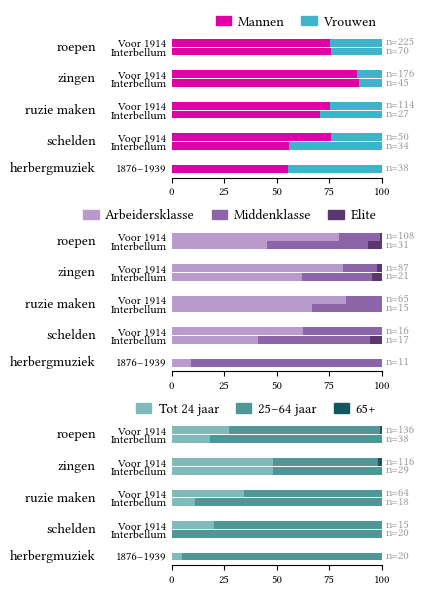

In [35]:
VIER = ["roepen", "zingen", "ruzie maken", "schelden"]
GEPOOLD = ["herbergmuziek"]
PERIODES = ["Voor 1914", "Interbellum"]
TOON = {"Voor 1914": "Voor WOI", "Interbellum": "Na WOI"}

# rijen: (praktijk, periodelabel, filter-op-periode?)
RIJEN, Y = [], []
y = 0
for p in VIER:
    for per in PERIODES:
        RIJEN.append((p, per, True)); Y.append(y); y += 1
    y += 1.6
for p in GEPOOLD:
    RIJEN.append((p, "1876–1939", False)); Y.append(y); y += 1

PANELEN = [
    ("gender", ["man", "woman"], ["Mannen", "Vrouwen"],
     [KLEUR_MAN, KLEUR_VROUW], "Gender"),

    ("klasse3", ["Arbeidersklasse", "Middenklasse", "Elite"],
     ["Arbeidersklasse", "Middenklasse", "Elite"],
     ["#B99ACD", "#8B65A8", "#5B376F"], "Sociale klasse"),

    ("leeftijd3", ["Tot 24 jaar", "25–64 jaar", "65+"],
    ["Tot 24 jaar", "25–64 jaar", "65+"],
    ["#80BABA", "#4F9696", "#14575C"], "Leeftijd"),
]

fig, axen = plt.subplots(3, 1, figsize=(TEKSTBREEDTE, 6.9))  # past binnen het tekstblok

for ax, (var, volgorde, labels, kleuren, titel) in zip(axen, PANELEN):
    d = kruis.dropna(subset=[var])

    for (praktijk, perlabel, filter_per), ypos in zip(RIJEN, Y):
        sel = d[d["praktijk"] == praktijk]
        if filter_per:
            sel = sel[sel["periode"] == perlabel]
        n = len(sel)
        if n == 0:
            continue
        aandeel = (sel[var].value_counts(normalize=True).mul(100)
                           .reindex(volgorde).fillna(0))

        links = 0
        for cat, kleur in zip(volgorde, kleuren):
            ax.barh(ypos, aandeel[cat], left=links, color=kleur, height=0.9)
            links += aandeel[cat]
        ax.text(102, ypos, f"n={n}", va="center", fontsize=CORPS_KLEIN, color=STEENGRIJS)

    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_yticks(Y)
    TOON = {"Voor 1914": "Voor 1914", "Interbellum": "Interbellum", "1877–1939": "1876–1939"}
    ax.set_yticklabels([TOON.get(r[1], r[1]) for r in RIJEN], fontsize=CORPS_KLEIN)
    ax.set_ylim(max(Y) + 1, min(Y) - 1)
    ax.spines[["left", "right"]].set_visible(False)
    ax.tick_params(axis="x", labelsize=CORPS_KLEIN)
    ax.tick_params(axis="y", length=0)

    posities_per_praktijk = {}
    for (praktijk, _, _), ypos in zip(RIJEN, Y):
        posities_per_praktijk.setdefault(praktijk, []).append(ypos)
    for praktijk, ys in posities_per_praktijk.items():
        ax.text(-0.36, np.mean(ys), praktijk, transform=ax.get_yaxis_transform(),
                ha="right", va="center", fontsize=CORPS)

    handles = [plt.Rectangle((0, 0), 1, 1, color=kl) for kl in kleuren]
    ax.legend(handles, labels, frameon=False, fontsize=CORPS, ncol=len(labels),
              loc="lower right", bbox_to_anchor=(100, min(Y) - 1.0),
              bbox_transform=ax.transData,
              columnspacing=1.2, handlelength=1.1, handletextpad=0.5,
              borderaxespad=0)

fig.subplots_adjust(hspace=0.35, left=0.26, right=0.88)
for ax in axen:
    pos = ax.get_position()
    ax.set_position([pos.x0, pos.y0, pos.width * 0.80, pos.height])

bewaar(fig, "8.12_sociaal_profiel_per_geluid")

In [36]:
for a, b in [("gender", "klasse3"), ("gender", "leeftijd3"), ("klasse3", "leeftijd3")]:
    d = kruis[kruis["praktijk"].isin(VIER)].dropna(subset=[a, b])
    print(f"\n=== {a} × {b} (n={len(d)}) ===")
    print(d.pivot_table(index="praktijk", columns="periode", values="aan",
                        aggfunc="count", fill_value=0).to_string())


=== gender × klasse3 (n=318) ===
periode      Interbellum  Voor 1914
praktijk                           
roepen                30         96
ruzie maken           13         53
schelden              13         14
zingen                16         83

=== gender × leeftijd3 (n=388) ===
periode      Interbellum  Voor 1914
praktijk                           
roepen                30        123
ruzie maken           17         60
schelden              13         13
zingen                23        109

=== klasse3 × leeftijd3 (n=257) ===
periode      Interbellum  Voor 1914
praktijk                           
roepen                21         81
ruzie maken           12         36
schelden               9         10
zingen                16         72


In [37]:
ALLE = ["roepen", "zingen", "ruzie maken", "schelden", "herbergmuziek",
        "deurbellen", "verkeer"]

for a, b in [("gender", "klasse3"), ("gender", "leeftijd3"), ("klasse3", "leeftijd3")]:
    d = kruis[kruis["praktijk"].isin(ALLE)].dropna(subset=[a, b])
    t = d.pivot_table(index=["praktijk", "periode"], columns=[a, b],
                      values="aan", aggfunc="count", fill_value=0, observed=True)
    print(f"\n{'=' * 70}\n{a} × {b}\n{'=' * 70}")
    print(t.to_string())
    print("\nn per rij:", t.sum(axis=1).to_dict())


gender × klasse3
gender                                man                              woman             
klasse3                   Arbeidersklasse Elite Middenklasse Arbeidersklasse Middenklasse
praktijk      periode                                                                    
deurbellen    Interbellum               3     0            1               0            0
              Voor 1914                 3     0            1               2            2
herbergmuziek Interbellum               1     0            3               0            4
              Voor 1914                 0     0            2               0            1
roepen        Interbellum              13     2            6               1            8
              Voor 1914                65     1           17              11            2
ruzie maken   Interbellum               8     0            5               0            0
              Voor 1914                40     0            9               2      

In [38]:
vr = w3_pers[(w3_pers["yelling"] == 1)
             & (w3_pers["periode"] == "Interbellum")
             & w3_pers["gender"].eq("woman")
             & w3_pers["klasse3"].eq("Middenklasse")]

beroepskolom = [c for c in w3_pers.columns if "prof" in c.lower()]
print("beroepskolommen:", beroepskolom)

print(vr[["year", "P_PROF_hisco", "P_PROF_hisclass"]].to_string())


beroepskolommen: ['P_PROF', 'P_PROF_match', 'P_PROF_hisco', 'P_PROF_hisclass']
        year P_PROF_hisco P_PROF_hisclass
553   1920.0        51020               5
959   1927.0        51020               5
965   1927.0          NaN               4
1003  1923.0        51020               5
1028  1923.0        51020               5
1029  1923.0        51020               5
1076  1931.0        51020               5
1112  1923.0        51020               5


In [39]:
sch = w3_pers[(w3_pers["scolding"] == 1)
              & (w3_pers["periode"] == "Interbellum")
              & w3_pers["gender"].eq("woman")]
print(sch[["year", "P_PROF", "P_PROF_hisco", "P_PROF_hisclass"]].to_string())

        year      P_PROF P_PROF_hisco P_PROF_hisclass
6     1937.0         NaN          NaN             NaN
7     1937.0    waaister        79510               9
9     1937.0         NaN          NaN             NaN
227   1926.0         NaN          NaN             NaN
228   1926.0         NaN          NaN             NaN
273   1930.0         NaN          NaN             NaN
811   1922.0         NaN          NaN             NaN
812   1922.0         NaN          NaN             NaN
861   1936.0         NaN          NaN             NaN
959   1927.0         NaN        51020               5
965   1927.0     koopman          NaN               4
979   1921.0  baanwerken        77190               9
1122  1927.0         NaN        51020               5
1450  1932.0         NaN          NaN             NaN
1482  1926.0         NaN          NaN             NaN


In [40]:
sch = w3_pers[w3_pers["scolding"] == 1].copy()

for per in ["Voor 1914", "Interbellum"]:
    for g in ["woman", "man"]:
        sel = sch[(sch["periode"] == per) & sch["gender"].eq(g)] \
                .drop_duplicates(subset=SLEUTEL).sort_values("year")
        print(f"\n{'=' * 70}\n{per} — {g} (n={len(sel)})\n{'=' * 70}")
        for _, r in sel.iterrows():
            print(f"\n--- {int(r['year'])} | {r['archive_file']} #{r['Incident Number']} "
                  f"| {r.get('P_PROF', '')} | {r.get('loc_street', '')} ---")
            print(str(r.get("text", ""))[:600])


Voor 1914 — woman (n=9)

--- 1881 | 731#1596 #1108.0 | leurster |  ---
Den 18 July 1881 v . 2 sell vrba t aan fisen D Dezen nacht hebben wy gezien en bestatig als dat de genaam Wuyt Jrank Catharina den Vrouw Delaet Jeannette oud 52 jaaren Woonachtig . Bontelmantel straat . N 0 leurster van beroep , beezig was met de nachtrust de stooren der inwoonders en ons zeggen naar dat wi haar al tot reven maal verwittigt hadden dat zy in haar huis moest gaan , als dat zy meester was van de roepen en de zeggen dat zi wilden zi riep smeerlappen en lariekend luit op tot aan al die verbei passeerden Balamt Pops

--- 1883 | 731#1601 #1048.0 | nan |  ---
Heden nacht in dienst zynde in het 2de kwaar rond 1 uren tier kommende op de Wapper brug ( hoorde wy vyf . mans persoonen , en een Vrouws persoon lanst zingende kommen , van uit de Schuttershof straat doen wij hun verboden als dat het verboden was van de nacht rust de storren begon zy met ons de spotten en nog meer lawyt de maaken , Wy zyn er achter g

In [41]:
sch = w3_pers[w3_pers["scolding"] == 1].copy()
sch["bureel"] = sch["text"].str.contains(
    r"bureel|bureele|gevang|opgesloten|aangehouden|boet|betalen|rijtuig|taxi",
    case=False, na=False)

print(sch.drop_duplicates(subset=SLEUTEL)
        .groupby(["periode", "gender"])["bureel"]
        .agg(["mean", "size"]).round(2).to_string())

                    mean  size
periode     gender            
Interbellum man     0.71     7
            woman   1.00     3
Voor 1914   man     0.55    11
            woman   0.25     4


In [42]:
print(len(sch), "rijen |", sch.drop_duplicates(subset=SLEUTEL).shape[0], "gebeurtenissen")
print(sch.groupby(["periode", "gender"])["bureel"].agg(["mean", "size"]).round(2))

145 rijen | 51 gebeurtenissen
                    mean  size
periode     gender            
Interbellum man     0.89    19
            woman   0.80    15
Voor 1914   man     0.42    38
            woman   0.08    12


In [43]:
df_meso = pd.read_excel("../../data/algemeen/gebeurtenisdata_meso/steekproefdatabank.xlsx")
d = df_meso.copy()
d["subcat"] = d["subcategory"].str.strip().str.lower()
d["periode"] = np.where(d["year"] <= 1914, "Voor 1914", "Interbellum")
d_nacht = d[d["E_TIME_astro"].isin(NACHTCATS)]

for naam, data in [("alle gebeurtenissen", d), ("nachtelijk", d_nacht)]:
    t = data.groupby("periode")["subcat"].value_counts().unstack(0).fillna(0)
    n = data.groupby("periode").size()
    print(f"\n=== {naam} ===")
    print(pd.DataFrame({
        "verbaal geweld": t.loc["verbaal geweld"],
        "N": n,
        "per 1.000": (t.loc["verbaal geweld"] / n * 1000).round(1),
    }).to_string())


=== alle gebeurtenissen ===
             verbaal geweld     N  per 1.000
periode                                     
Interbellum            11.0   898       12.2
Voor 1914              97.0  4942       19.6

=== nachtelijk ===
             verbaal geweld     N  per 1.000
periode                                     
Interbellum             4.0   202       19.8
Voor 1914              60.0  1929       31.1
